# new metrics

## matching treatment-control pair based on metrics -6 months from HN submission date (month 0)

In [ ]:
import pandas as pd
import numpy as np
from tqdm import tqdm
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

# Load datasets
treatment_metrics = pd.read_csv("../../dataset/hn-stories-gh-ai-metrics-[6months-before-after-hn]-cumulative-v2.csv", encoding="utf-7")
treatment_metadata = pd.read_csv("../../dataset/hn-stories-gh-ai-metadata-[6months-before-after-hn]-v2.csv")

control_metrics = pd.read_csv("../../dataset/nonhn-gh-ai-metrics-[2147].csv", encoding="utf-7")
control_metadata = pd.read_csv("../../dataset/nonhn-gh-ai-metadata-[2147].csv")

# Convert date columns
treatment_metrics['month']  = pd.to_datetime(treatment_metrics['month'], utc=True)
treatment_metrics['hn_submission_date'] = pd.to_datetime(treatment_metrics['hn_submission_date'], utc=True)
treatment_metadata['repo_creation_date'] = pd.to_datetime(treatment_metadata['repo_creation_date'], utc=True)
control_metrics['month']    = pd.to_datetime(control_metrics['month'], utc=True)
control_metadata['repo_creation_date']  = pd.to_datetime(control_metadata['repo_creation_date'], utc=True)

# Metrics to match
metrics = ['new_forks', 'new_stars', 'new_commits', 'new_prs', 'active_contributors']

# Earliest available metrics date (May 2022)
earliest_metrics_date = pd.Timestamp('2022-05-01', tz='UTC')


In [2]:
# Function to find best control match
def find_best_match(treatment_row, metric):
    """Finds the best matching control repository based on the specified metric over available months."""
    hn_submission_date = treatment_row['hn_submission_date']
    treatment_repo = treatment_row['repo_full_name']
    treatment_repo_url = treatment_row['repo_url']

    # Get treatment repo creation date
    creation = treatment_metadata.loc[treatment_metadata['repo_full_name'] == treatment_repo, 'repo_creation_date']
    if creation.empty:
        return None
    treatment_creation_date = creation.iloc[0]

    # Define 6-month period before submission (or use available data if cut off)
    start_date = max(earliest_metrics_date, hn_submission_date - pd.DateOffset(months=6))
    end_date = hn_submission_date - pd.DateOffset(months=1)

    # Filter treatment data for available months
    treatment_subset = treatment_metrics[
        (treatment_metrics['repo_full_name'] == treatment_repo) &
        (treatment_metrics['month'] >= start_date) &
        (treatment_metrics['month'] <= end_date)
    ]

    if treatment_subset.empty:
        return None

    # Determine how many months are available
    num_available_months = treatment_subset['month'].nunique()

    # Get treatment metric values as a vector
    treatment_values = treatment_subset[metric].values.reshape(1, -1)

    # Find control repos created before start_date
    valid_controls = control_metadata[control_metadata['repo_creation_date'] <= start_date]
    valid_control_names = set(valid_controls['repo_full_name'])

    # Filter control repos with valid metrics
    control_subset = control_metrics[
        (control_metrics['control_repo'].isin(valid_control_names)) &
        (control_metrics['month'] >= start_date) &
        (control_metrics['month'] <= end_date)
    ]

    if control_subset.empty:
        return None

    # Reshape control data into time-series format (only for available months)
    control_time_series = control_subset.pivot(index='month', columns='control_repo', values=metric).fillna(0)

    # Keep only control repos with at least the same number of months as treatment repo
    valid_control_repos = control_time_series.columns[control_time_series.count(axis=0) >= num_available_months]
    control_time_series = control_time_series[valid_control_repos]

    if control_time_series.shape[1] == 0:
        return None

    # Compute cosine similarity
    control_vectors = control_time_series.T.values  # Convert to array (each row = available-month vector)

    # Inside find_best_match function, replace the similarity calculation and selection
    similarities = cosine_similarity(treatment_values, control_vectors)[0]
    euclidean_dists = euclidean_distances(treatment_values, control_vectors)[0]

    # Define thresholds (adjust these values based on your data)
    cosine_threshold = 0.85  # Higher is better for cosine
    euclidean_threshold = 20.0  # Lower is better for euclidean

    # Find candidates that meet both criteria
    valid_matches = []
    for i in range(len(similarities)):
        if similarities[i] >= cosine_threshold and euclidean_dists[i] <= euclidean_threshold:
            valid_matches.append((i, similarities[i], euclidean_dists[i]))

    if not valid_matches:
        return None  # Skip if no matches meet both thresholds

    # Sort by cosine similarity (descending) as primary criterion
    valid_matches.sort(key=lambda x: x[1], reverse=True)
    best_idx = valid_matches[0][0]

    # Continue with existing code to get best match details
    best_match_repo = control_time_series.columns[best_idx]
    best_match_metadata = control_metadata[control_metadata['repo_full_name'] == best_match_repo].iloc[0]

    # Include both similarity scores in the result
    return [
        treatment_repo, treatment_repo_url, hn_submission_date,
        treatment_creation_date, treatment_values.sum(), treatment_row['new_forks'],
        best_match_repo, best_match_metadata['repo_creation_date'],
        control_time_series.iloc[:, best_idx].sum(), best_match_metadata['fork_count'],
        similarities[best_idx], euclidean_dists[best_idx], 1  # Added euclidean distance
    ]

# Process each metric separately
for metric in metrics:
    print(f"\nProcessing metric: {metric}")
    results = []

    for _, treatment_row in tqdm(
        treatment_metrics.drop_duplicates(subset=['repo_full_name']).iterrows(),
        total=treatment_metrics['repo_full_name'].nunique(),
        desc=f"Matching {metric}"
    ):
        match = find_best_match(treatment_row, metric)
        if match:
            results.append(match)

    # Save results
    if results:
        df_results = pd.DataFrame(results, columns=[
            "treatment_repo", "treatment_repo_url", "hn_submission_date",
            "treatment_creation_date", f"treatment_{metric}", "treatment_forks",
            "control_repo", "control_creation_date", f"control_{metric}", "control_forks",
            "similarity_score", "euclidean_distance", "ranking"
        ])
        df_results.to_csv(f"matched_control_{metric}.csv", index=False)
    else:
        print(f"No matches found for {metric}.")



Processing metric: new_forks


Matching new_forks: 100%|██████████| 147/147 [00:01<00:00, 96.20it/s]



Processing metric: new_stars


Matching new_stars: 100%|██████████| 147/147 [00:01<00:00, 94.07it/s]



Processing metric: new_commits


Matching new_commits: 100%|██████████| 147/147 [00:01<00:00, 96.48it/s]



Processing metric: new_prs


Matching new_prs: 100%|██████████| 147/147 [00:01<00:00, 99.10it/s]



Processing metric: active_contributors


Matching active_contributors: 100%|██████████| 147/147 [00:01<00:00, 94.19it/s]


## visualizing parallel trend

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

metrics = ['new_stars', 'new_forks', 'new_commits', 'new_prs', 'active_contributors']

# Load the original metric data
df_treatment = pd.read_csv("../../dataset/hn-stories-gh-ai-metrics-[6months-before-after-hn]-cumulative-v2.csv", encoding="utf-7")
df_control = pd.read_csv("../../dataset/nonhn-gh-ai-metrics-[2147].csv", encoding="utf-7")


/tmp/ipykernel_30050/2401542717.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


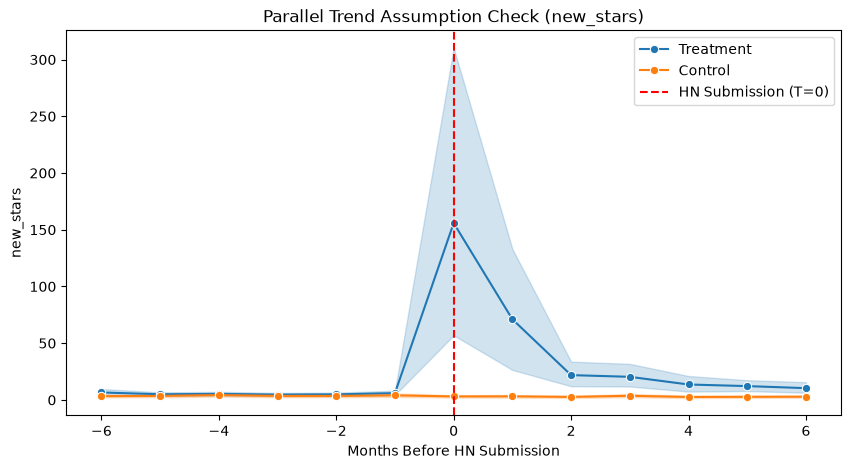

/tmp/ipykernel_30050/2401542717.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


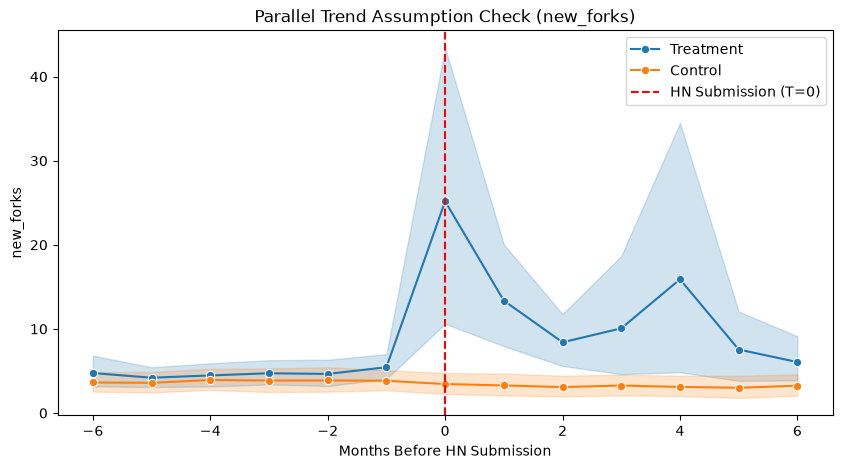

/tmp/ipykernel_30050/2401542717.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


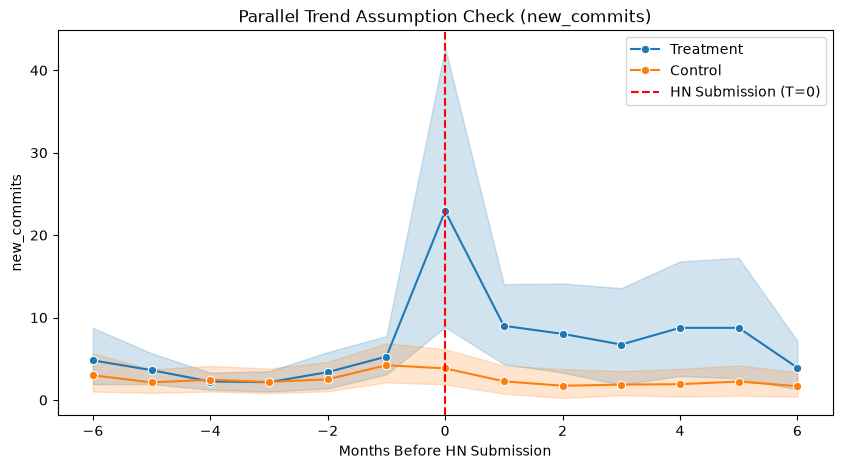

/tmp/ipykernel_30050/2401542717.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


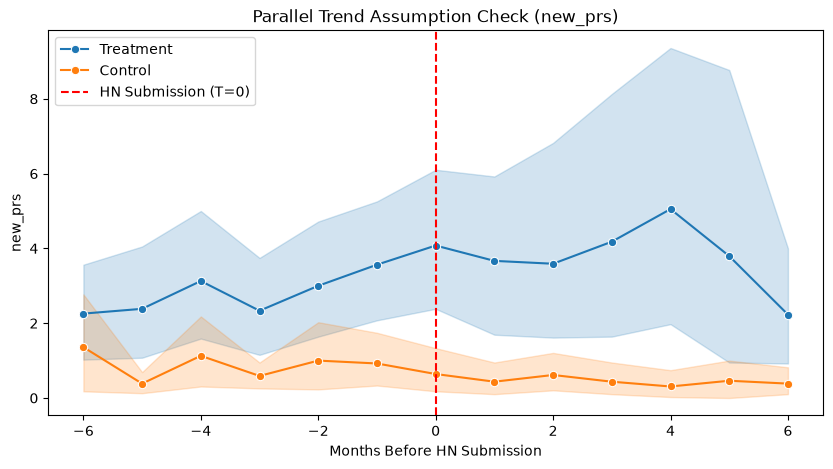

/tmp/ipykernel_30050/2401542717.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


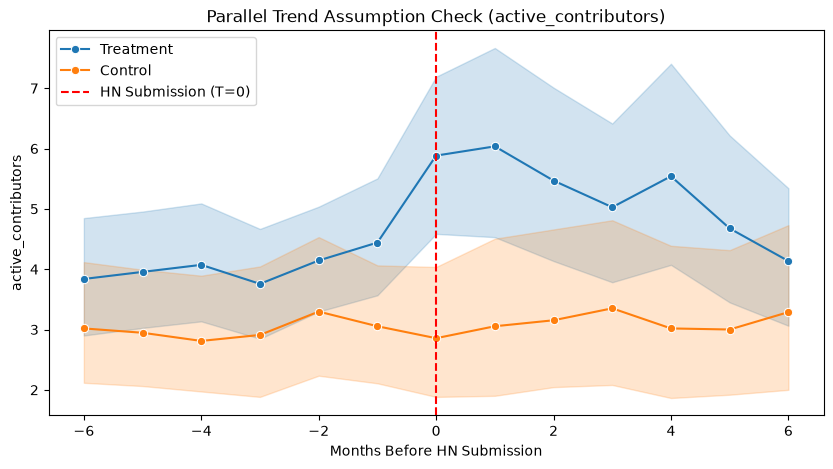

In [5]:
# Align time: Convert dates to relative months
def align_time(df, hn_date):
    hn_date = hn_date.tz_localize(None)  # Remove timezone
    df['relative_month'] = df['month'].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
    return df

# Aggregate trends: Average over all repos
def plot_aggregate_trend(metric):
    plt.figure(figsize=(10, 5))

    sns.lineplot(
        data=df_aligned,
        x="relative_month",
        y=metric,
        hue="repo_type",
        ci=95,  # Confidence interval
        marker="o"
    )
    # increase font size

    plt.axvline(x=0, color='red', linestyle='dashed', label="HN Submission (T=0)")
    plt.xlabel("Months Before HN Submission")
    plt.ylabel(metric)
    plt.title(f"Parallel Trend Assumption Check ({metric})")
    plt.legend()
    plt.show()

for metric in metrics:
    # Load matched treatment-control data
    df_matched = pd.read_csv(f".//matched_control_{metric}.csv")  # Adjust filename as needed

    # Convert date columns
    df_treatment['month'] = pd.to_datetime(df_treatment['month'])
    df_control['month'] = pd.to_datetime(df_control['month'])
    df_matched['hn_submission_date'] = pd.to_datetime(df_matched['hn_submission_date'])

    # Store aligned trends for aggregation
    aligned_treatment = []
    aligned_control = []

    # Iterate through matched pairs
    for _, row in df_matched.iterrows():
        treatment_repo = row['treatment_repo']
        control_repo = row['control_repo']
        hn_date = row['hn_submission_date']

        # Align treatment repo data
        treatment_data = df_treatment[df_treatment['repo_full_name'] == treatment_repo].copy()
        treatment_data = align_time(treatment_data, hn_date)
        treatment_data['repo_type'] = 'Treatment'
        aligned_treatment.append(treatment_data)

        # Align control repo data
        control_data = df_control[df_control['control_repo'] == control_repo].copy()
        control_data = align_time(control_data, hn_date)
        control_data['repo_type'] = 'Control'
        aligned_control.append(control_data)

    # Combine aligned data
    df_aligned = pd.concat(aligned_treatment + aligned_control, ignore_index=True)

    # Ensure relative_month is an integer for filtering
    df_aligned['relative_month'] = df_aligned['relative_month'].astype(int)

    # Filter for pre-submission period (T = -6 to -1)
    df_aligned = df_aligned[(df_aligned['relative_month'] >= -6) & (df_aligned['relative_month'] <= 6)]

    plot_aggregate_trend(metric)


In [8]:
import pandas as pd
import statsmodels.api as sm
import scipy.stats as stats

# Load datasets
df_treatment = pd.read_csv("../../dataset/hn-stories-gh-ai-metrics-cumulative.csv", encoding="utf-7")
df_control = pd.read_csv("../../dataset/nonhn-gh-ai-metrics-cumulative.csv", encoding="utf-7")
# df_treatment = pd.read_csv("../dataset/hn-stories-gh-ai-metrics-[6months-before-after-hn].csv")
# df_control = pd.read_csv("../dataset/nonhn-gh-ai-metrics-[2147].csv", encoding="utf-7")

# Convert date columns
df_treatment['month'] = pd.to_datetime(df_treatment['month'])
df_control['month'] = pd.to_datetime(df_control['month'])

# List of metrics to analyze
# metrics = ['cumulative_stars', 'cumulative_forks', 'cumulative_commits', 'cumulative_prs', 'cumulative_ve_contributors']
metrics = ['new_stars', 'new_forks', 'new_commits', 'new_prs', 'active_contributors']


# Function to align time with HN submission date
def align_time(df, hn_date):
    hn_date = hn_date.tz_localize(None)
    df = df.copy()
    df['relative_month'] = df['month'].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
    return df

# Store results
trend_results = []
balancing_results = []

# Iterate through metrics
for metric in metrics:
    # Load matched treatment-control data
    df_matched = pd.read_csv(f"./matched_control_{metric}.csv")

    aligned_treatment, aligned_control = [], []

    # Iterate through matched pairs
    for _, row in df_matched.iterrows():
        treatment_repo = row['treatment_repo']
        control_repo = row['control_repo']
        hn_date = pd.to_datetime(row['hn_submission_date'])

        # Align treatment repo data
        treatment_data = df_treatment[df_treatment['repo_full_name'] == treatment_repo].copy()
        treatment_data = align_time(treatment_data, hn_date)
        treatment_data['repo_type'] = 'Treatment'
        aligned_treatment.append(treatment_data)

        # Align control repo data
        control_data = df_control[df_control['control_repo'] == control_repo].copy()
        control_data = align_time(control_data, hn_date)
        control_data['repo_type'] = 'Control'
        aligned_control.append(control_data)

    # Combine data
    df_aligned = pd.concat(aligned_treatment + aligned_control, ignore_index=True)
    df_aligned['relative_month'] = df_aligned['relative_month'].astype(int)

    # Filter for pre-submission period (-6 to -1)
    df_pre_treatment = df_aligned.loc[(df_aligned['relative_month'] >= -6) & (df_aligned['relative_month'] <= -1)].copy()
    df_pre_treatment.loc[:, 'time'] = df_pre_treatment['relative_month']  # Fix warning

    # --- Group-Specific Linear Trends ---
    for group in ['Treatment', 'Control']:
        df_group = df_pre_treatment[df_pre_treatment['repo_type'] == group]
        X = sm.add_constant(df_group['time'])
        y = df_group[metric]

        model = sm.OLS(y, X).fit()
        trend_results.append({'Metric': metric, 'Group': group, 'Slope': model.params['time']})

    # --- Balancing Test ---
    treatment_vals = df_pre_treatment[df_pre_treatment['repo_type'] == 'Treatment'][metric]
    control_vals = df_pre_treatment[df_pre_treatment['repo_type'] == 'Control'][metric]

    t_stat, p_value = stats.ttest_ind(treatment_vals, control_vals, equal_var=False)  # Welch’s t-test
    balancing_results.append({'Metric': metric, 'p-value': p_value})

# Convert results to DataFrames for better formatting
df_trends = pd.DataFrame(trend_results)
df_balancing = pd.DataFrame(balancing_results)

# Output results
print("\nGroup-Specific Linear Trends (Pre-Treatment Slopes):")
print(df_trends.to_string(index=False))

print("\nBalancing Test p-values:")
print(df_balancing.to_string(index=False))



Group-Specific Linear Trends (Pre-Treatment Slopes):
             Metric     Group     Slope
          new_stars Treatment -0.108095
          new_stars   Control  0.079524
          new_forks Treatment  0.144874
          new_forks   Control  0.050756
        new_commits Treatment  0.042471
        new_commits   Control  0.198456
            new_prs Treatment  0.216850
            new_prs   Control -0.024908
active_contributors Treatment  0.093436
active_contributors   Control  0.038095

Balancing Test p-values:
             Metric      p-value
          new_stars 4.126561e-04
          new_forks 2.476113e-02
        new_commits 1.766234e-01
            new_prs 3.765195e-07
active_contributors 4.252314e-04


## prepare dataset for -6 months and +6 months from HN submission date

In [9]:
import pandas as pd
from dateutil.relativedelta import relativedelta
import os

# Config
metrics = ['new_stars', 'new_forks', 'new_commits', 'new_prs', 'active_contributors']
output_dir = "aligned_did_outputs_new"
os.makedirs(output_dir, exist_ok=True)

# Load full cumulative metric files
df_treatment = pd.read_csv("../../dataset/hn-stories-gh-ai-metrics-[6months-before-after-hn]-cumulative-v2.csv", encoding="utf-7")
df_control = pd.read_csv("../../dataset/nonhn-gh-ai-metrics-[2147].csv", encoding="utf-7")


In [10]:

# Convert date columns
df_treatment['month'] = pd.to_datetime(df_treatment['month'])
df_control['month'] = pd.to_datetime(df_control['month'])

def align_time(df, hn_date):
    hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
    df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
    df["post_treatment"] = df["relative_month"].apply(lambda x: 1 if x >= 0 else 0)
    return df

for metric in metrics:
    df_matched = pd.read_csv(f"./matched_control_{metric}.csv", parse_dates=["hn_submission_date"])

    all_rows = []

    for _, row in df_matched.iterrows():
        treatment_repo = row['treatment_repo']
        control_repo = row['control_repo']
        hn_date = row['hn_submission_date']

        # Align treatment data
        treatment_data = df_treatment[df_treatment['repo_full_name'] == treatment_repo].copy()
        if treatment_data.empty:
            print(f"[Warning] No treatment data for: {treatment_repo}")
            continue

        treatment_data = align_time(treatment_data, hn_date)
        treatment_data["repo_type"] = "treatment"

        # Align control data
        control_data = df_control[df_control['control_repo'] == control_repo].copy()
        if control_data.empty:
            print(f"[Warning] No control data for: {control_repo}")
            continue

        control_data = align_time(control_data, hn_date)
        control_data["repo_type"] = "control"
        control_data = control_data.rename(columns={"control_repo": "repo_full_name"})

        # Combine
        combined = pd.concat([treatment_data, control_data], ignore_index=True)
        combined["pair_id"] = f"{treatment_repo}__vs__{control_repo}"
        all_rows.append(combined)

    if all_rows:
        df_final = pd.concat(all_rows, ignore_index=True)
        df_final = df_final[df_final['relative_month'].between(-6, 6)]
        df_final.to_csv(f"{output_dir}/aligned_did_{metric}.csv", index=False)
        print(f"[✓] Saved aligned_did_{metric}.csv")
    else:
        print(f"[x] No data found for {metric} — file skipped.")


/tmp/ipykernel_30050/725016261.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/725016261.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
/tmp/ipykernel_30050/725016261.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/725016261.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("

[✓] Saved aligned_did_new_stars.csv


/tmp/ipykernel_30050/725016261.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/725016261.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
/tmp/ipykernel_30050/725016261.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/725016261.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("

[✓] Saved aligned_did_new_forks.csv


/tmp/ipykernel_30050/725016261.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/725016261.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
/tmp/ipykernel_30050/725016261.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/725016261.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("

...

/tmp/ipykernel_30050/725016261.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/725016261.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
/tmp/ipykernel_30050/725016261.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/725016261.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("

[✓] Saved aligned_did_new_prs.csv


/tmp/ipykernel_30050/725016261.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/725016261.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
/tmp/ipykernel_30050/725016261.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/725016261.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("

[✓] Saved aligned_did_active_contributors.csv


/tmp/ipykernel_30050/725016261.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/725016261.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
/tmp/ipykernel_30050/725016261.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/725016261.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("

## export graphs
cross checking - generating PTA graph using the new relative-months file

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

aligned_dir = "aligned_did_outputs_new"
metrics = ['new_stars', 'new_forks', 'new_commits', 'new_prs', 'active_contributors']
metric_column_map = {
    "new_stars": "new_stars",
    "new_forks": "new_forks",
    "new_commits": "new_commits",
    "new_prs": "new_prs",
    "active_contributors": "active_contributors"
}


/tmp/ipykernel_30050/3088985354.py:17: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


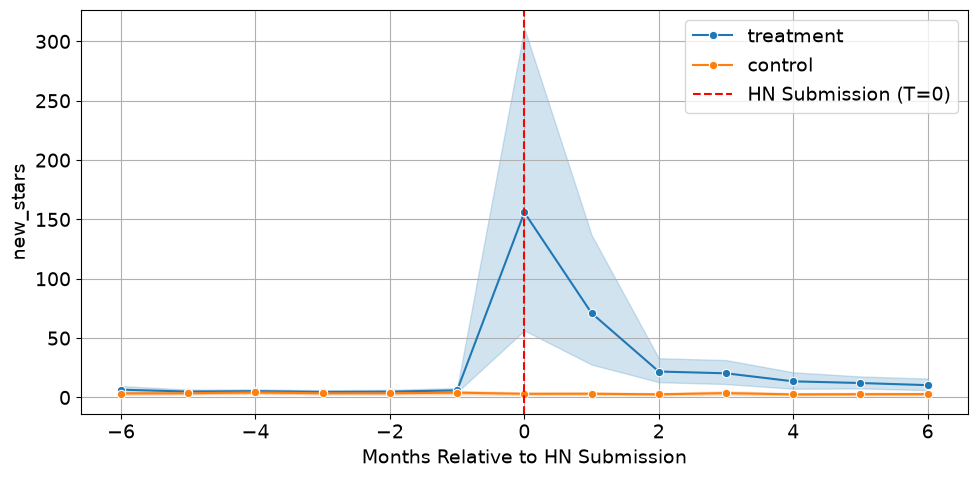

/tmp/ipykernel_30050/3088985354.py:17: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


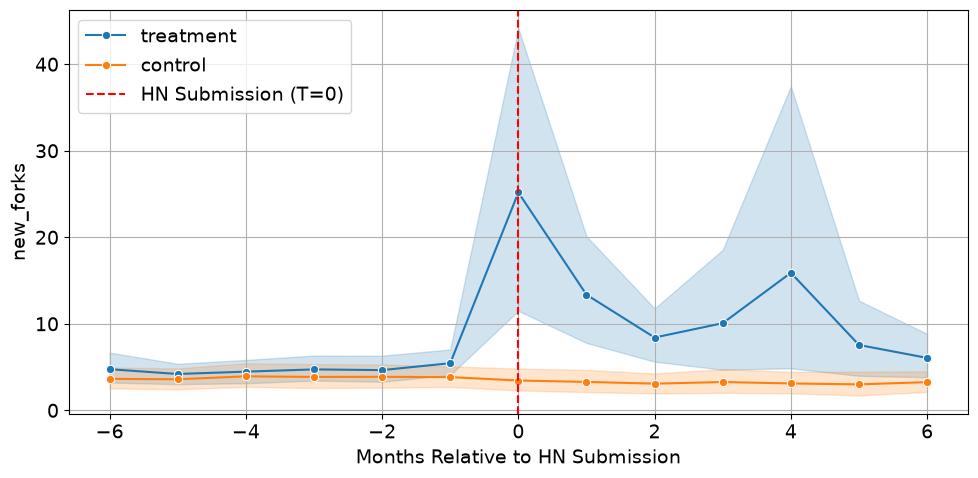

/tmp/ipykernel_30050/3088985354.py:17: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


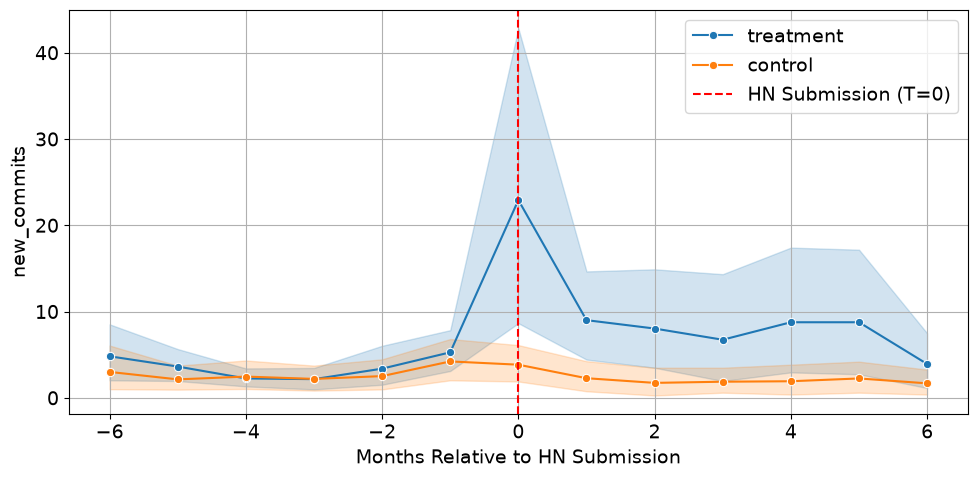

/tmp/ipykernel_30050/3088985354.py:17: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


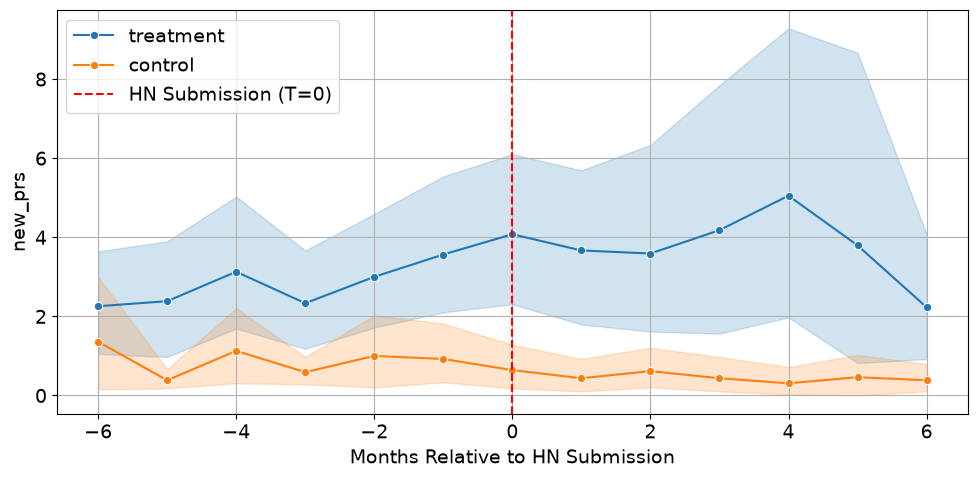

/tmp/ipykernel_30050/3088985354.py:17: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


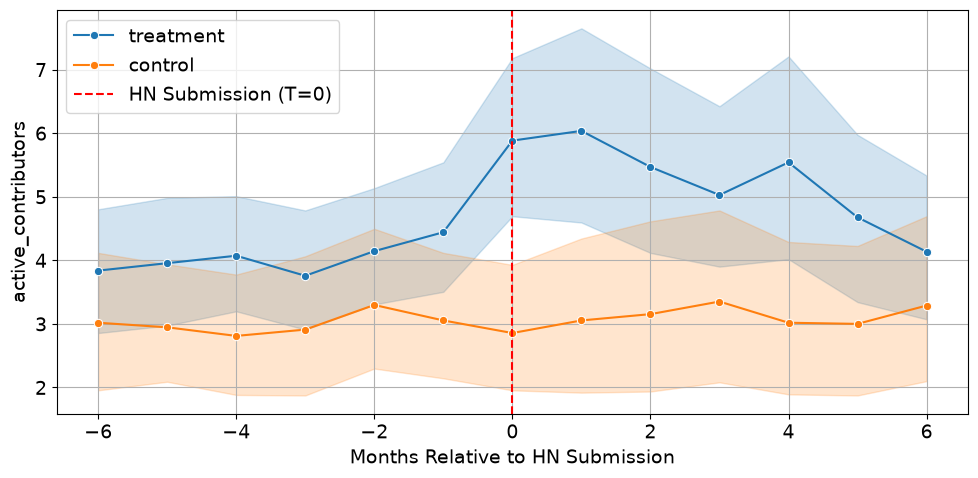

In [34]:
# Plot function
def plot_aggregate_trend(metric_key):
    file_path = os.path.join(aligned_dir, f"aligned_did_{metric_key}.csv")
    if not os.path.exists(file_path):
        print(f"[!] File not found: {file_path}")
        return

    df = pd.read_csv(file_path)
    if df.empty:
        print(f"[!] Empty data in {file_path}")
        return

    df["relative_month"] = df["relative_month"].astype(int)
    metric_col = metric_column_map[metric_key]

    plt.figure(figsize=(10, 5))
    sns.lineplot(
        data=df,
        x="relative_month",
        y=metric_col,
        hue="repo_type",
        ci=95,
        marker="o"
    )
    # increase font size
    plt.rcParams.update({'font.size': 14})

    plt.axvline(x=0, color='red', linestyle='dashed', label="HN Submission (T=0)")
    plt.xlabel("Months Relative to HN Submission")
    plt.ylabel(metric_col)
    # plt.title(f"Parallel Trend Check (Cumulative {metric_key.title()})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"plots/parallel_trend_check_{metric_key}.pdf")
    plt.show()

# Run for each metric
for metric in metrics:
    plot_aggregate_trend(metric)


## export graphs - show outliers

C:\Users\prach\AppData\Local\Temp\ipykernel_30600\1754197917.py:59: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


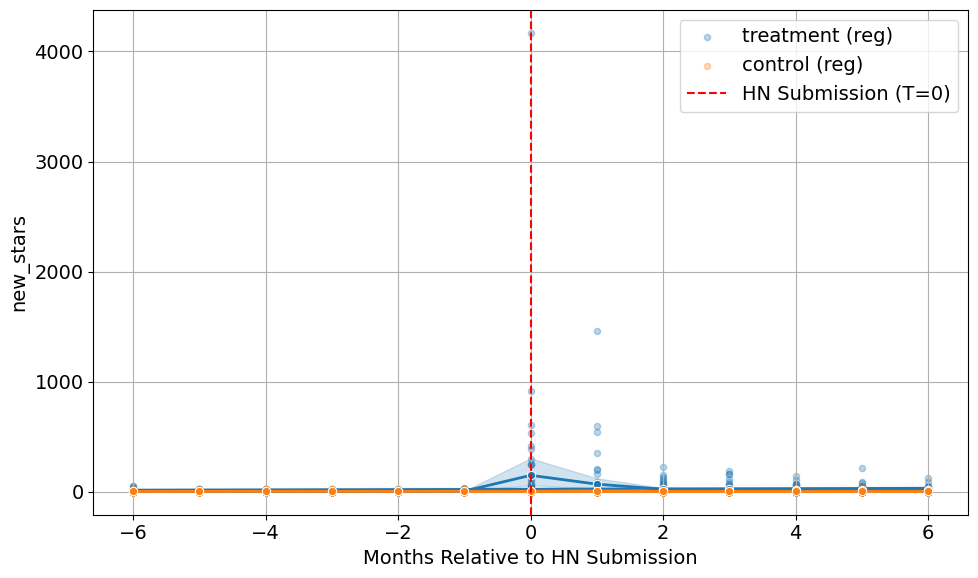

C:\Users\prach\AppData\Local\Temp\ipykernel_30600\1754197917.py:59: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


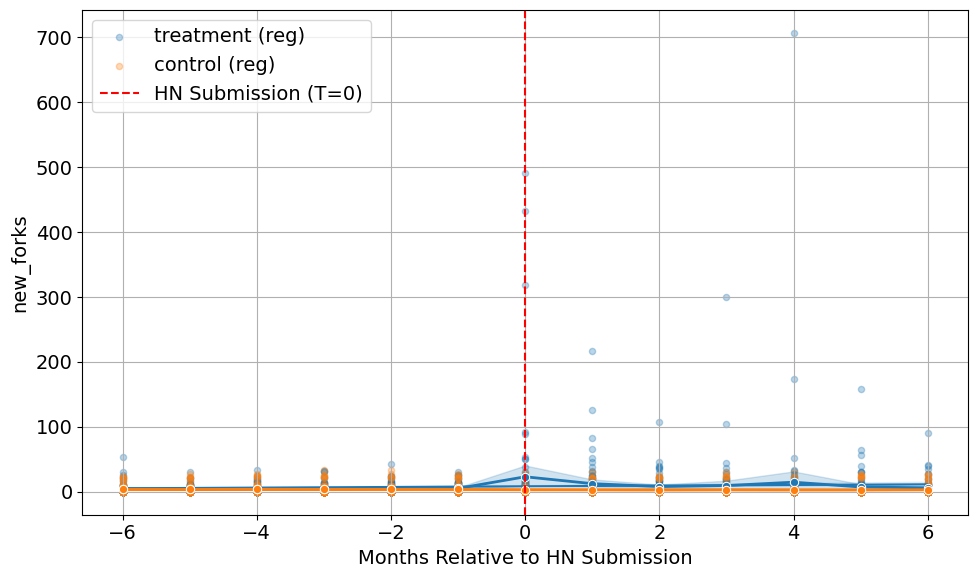

C:\Users\prach\AppData\Local\Temp\ipykernel_30600\1754197917.py:59: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


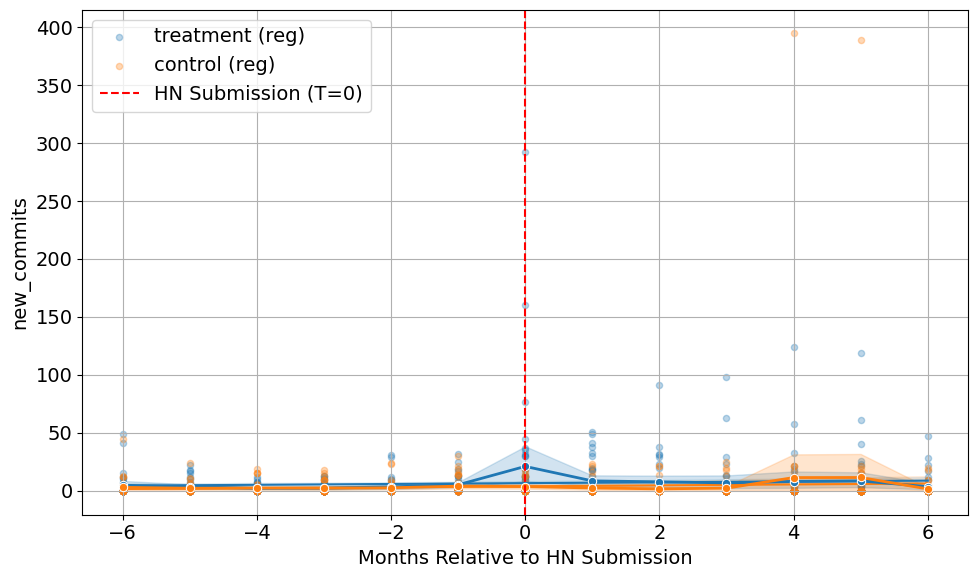

C:\Users\prach\AppData\Local\Temp\ipykernel_30600\1754197917.py:59: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


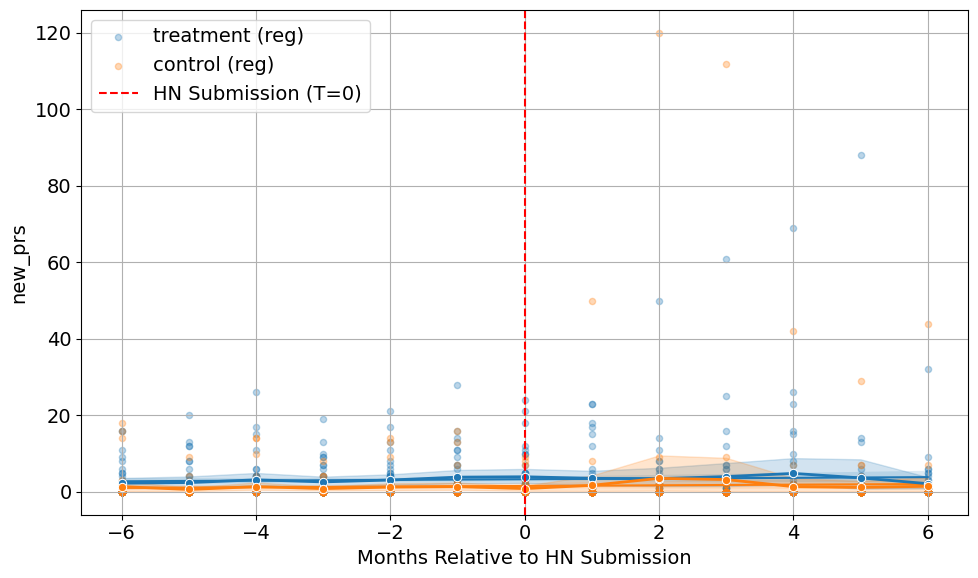

C:\Users\prach\AppData\Local\Temp\ipykernel_30600\1754197917.py:59: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


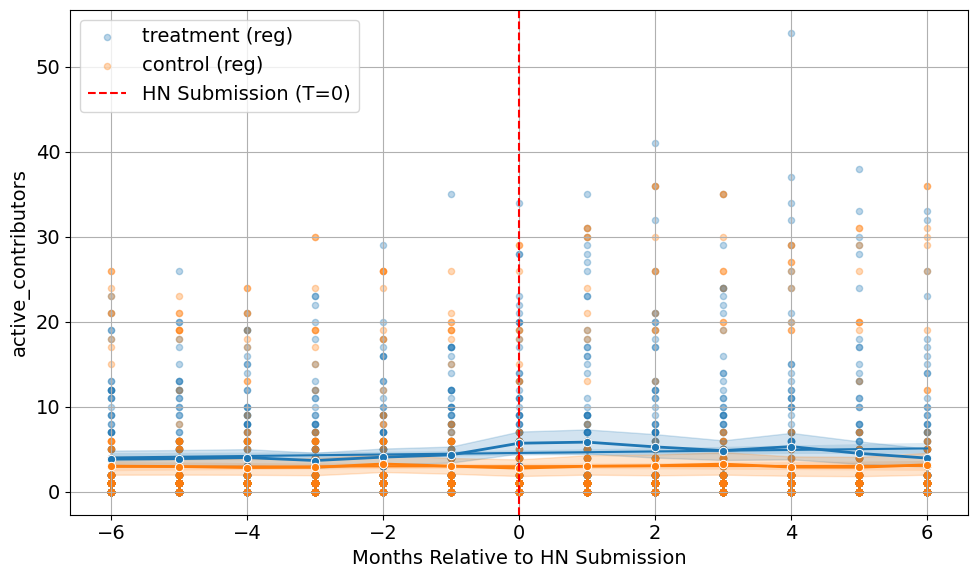

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

aligned_dir = "aligned_did_outputs_new"
metrics = ['new_stars', 'new_forks', 'new_commits', 'new_prs', 'active_contributors']
metric_column_map = {
    "new_stars": "new_stars",
    "new_forks": "new_forks",
    "new_commits": "new_commits",
    "new_prs": "new_prs",
    "active_contributors": "active_contributors"
}

# Plot function
def plot_aggregate_trend(metric_key):
    file_path = os.path.join(aligned_dir, f"aligned_did_{metric_key}.csv")
    if not os.path.exists(file_path):
        print(f"[!] File not found: {file_path}")
        return

    df = pd.read_csv(file_path)
    if df.empty:
        print(f"[!] Empty data in {file_path}")
        return

    df["relative_month"] = df["relative_month"].astype(int)
    metric_col = metric_column_map[metric_key]

    plt.figure(figsize=(10, 6))

    # Scatterplot with regression line, split by group
    for repo_type in df["repo_type"].unique():
        subset = df[df["repo_type"] == repo_type]
        sns.regplot(
            data=subset,
            x="relative_month",
            y=metric_col,
            scatter=True,
            lowess=False,
            label=f"{repo_type} (reg)",
            scatter_kws={'alpha':0.3, 's':20},
            line_kws={'linewidth':1.5}
        )

    # Original lineplot for smoothed group means
    sns.lineplot(
        data=df,
        x="relative_month",
        y=metric_col,
        hue="repo_type",
        ci=95,
        marker="o",
        linewidth=2,
        legend=False  # Already have labels from regplot
    )
    # increase font size
    plt.rcParams.update({'font.size': 14})

    plt.axvline(x=0, color='red', linestyle='dashed', label="HN Submission (T=0)")
    plt.xlabel("Months Relative to HN Submission")
    plt.ylabel(metric_col)
    # plt.title(f"Parallel Trend Check with Scatter & Regression\n(Cumulative {metric_key.title()})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"plots/parallel_trend_check_with_scatter_{metric_key}.pdf")
    plt.show()

# Run for each metric
for metric in metrics:
    plot_aggregate_trend(metric)


# cumulative

## matching treatment-control pair based on metrics -6 months from HN submission date (month 0)

In [11]:
# Load datasets
treatment_metrics = pd.read_csv("../../dataset/hn-stories-gh-ai-metrics-[6months-before-after-hn]-cumulative-v2.csv", encoding="utf-7")
treatment_metadata = pd.read_csv("../../dataset/hn-stories-gh-ai-metadata-[6months-before-after-hn]-v2.csv")

control_metrics = pd.read_csv("../../dataset/nonhn-gh-ai-metrics-cumulative.csv", encoding="utf-7")
control_metadata = pd.read_csv("../../dataset/nonhn-gh-ai-metadata-[2147].csv")

# Convert date columns
treatment_metrics['month']  = pd.to_datetime(treatment_metrics['month'], utc=True)
treatment_metrics['hn_submission_date'] = pd.to_datetime(treatment_metrics['hn_submission_date'], utc=True)
treatment_metadata['repo_creation_date'] = pd.to_datetime(treatment_metadata['repo_creation_date'], utc=True)
control_metrics['month']    = pd.to_datetime(control_metrics['month'], utc=True)
control_metadata['repo_creation_date']  = pd.to_datetime(control_metadata['repo_creation_date'], utc=True)

# Metrics to match
metrics = ['cumulative_stars', 'cumulative_forks', 'cumulative_commits', 'cumulative_prs', 'cumulative_ve_contributors']

# Earliest available metrics date (May 2022)
earliest_metrics_date = pd.Timestamp('2022-05-01', tz='UTC')


In [12]:
import pandas as pd
import numpy as np
from tqdm import tqdm
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

# Function to find best control match
def find_best_match(treatment_row, metric):
    """Finds the best matching control repository based on the specified metric over available months."""
    hn_submission_date = treatment_row['hn_submission_date']
    treatment_repo = treatment_row['repo_full_name']
    treatment_repo_url = treatment_row['repo_url']

    # Get treatment repo creation date
    creation = treatment_metadata.loc[treatment_metadata['repo_full_name'] == treatment_repo, 'repo_creation_date']
    if creation.empty:
        return None
    treatment_creation_date = creation.iloc[0]

    # Define 6-month period before submission (or use available data if cut off)
    start_date = max(earliest_metrics_date, hn_submission_date - pd.DateOffset(months=6))
    end_date = hn_submission_date - pd.DateOffset(months=1)

    # Filter treatment data for available months
    treatment_subset = treatment_metrics[
        (treatment_metrics['repo_full_name'] == treatment_repo) &
        (treatment_metrics['month'] >= start_date) &
        (treatment_metrics['month'] <= end_date)
    ]

    if treatment_subset.empty:
        return None

    # Determine how many months are available
    num_available_months = treatment_subset['month'].nunique()

    # Get treatment metric values as a vector
    treatment_values = treatment_subset[metric].values.reshape(1, -1)

    # Find control repos created before start_date
    valid_controls = control_metadata[control_metadata['repo_creation_date'] <= start_date]
    valid_control_names = set(valid_controls['repo_full_name'])

    # Filter control repos with valid metrics
    control_subset = control_metrics[
        (control_metrics['control_repo'].isin(valid_control_names)) &
        (control_metrics['month'] >= start_date) &
        (control_metrics['month'] <= end_date)
    ]

    if control_subset.empty:
        return None

    # Reshape control data into time-series format (only for available months)
    control_time_series = control_subset.pivot(index='month', columns='control_repo', values=metric).fillna(0)

    # Keep only control repos with at least the same number of months as treatment repo
    valid_control_repos = control_time_series.columns[control_time_series.count(axis=0) >= num_available_months]
    control_time_series = control_time_series[valid_control_repos]

    if control_time_series.shape[1] == 0:
        return None

    # Compute cosine similarity
    control_vectors = control_time_series.T.values  # Convert to array (each row = available-month vector)

    # Inside find_best_match function, replace the similarity calculation and selection
    similarities = cosine_similarity(treatment_values, control_vectors)[0]
    euclidean_dists = euclidean_distances(treatment_values, control_vectors)[0]

    # Define thresholds (adjust these values based on your data)
    cosine_threshold = 0.85  # Higher is better for cosine
    euclidean_threshold = 20.0  # Lower is better for euclidean

    # Find candidates that meet both criteria
    valid_matches = []
    for i in range(len(similarities)):
        if similarities[i] >= cosine_threshold and euclidean_dists[i] <= euclidean_threshold:
            valid_matches.append((i, similarities[i], euclidean_dists[i]))

    if not valid_matches:
        return None  # Skip if no matches meet both thresholds

    # Sort by cosine similarity (descending) as primary criterion
    valid_matches.sort(key=lambda x: x[1], reverse=True)
    best_idx = valid_matches[0][0]

    # Continue with existing code to get best match details
    best_match_repo = control_time_series.columns[best_idx]
    best_match_metadata = control_metadata[control_metadata['repo_full_name'] == best_match_repo].iloc[0]

    # Include both similarity scores in the result
    return [
        treatment_repo, treatment_repo_url, hn_submission_date,
        treatment_creation_date, treatment_values.sum(), treatment_row['new_forks'],
        best_match_repo, best_match_metadata['repo_creation_date'],
        control_time_series.iloc[:, best_idx].sum(), best_match_metadata['fork_count'],
        similarities[best_idx], euclidean_dists[best_idx], 1  # Added euclidean distance
    ]

# Process each metric separately
for metric in metrics:
    print(f"\nProcessing metric: {metric}")
    results = []

    for _, treatment_row in tqdm(
        treatment_metrics.drop_duplicates(subset=['repo_full_name']).iterrows(),
        total=treatment_metrics['repo_full_name'].nunique(),
        desc=f"Matching {metric}"
    ):
        match = find_best_match(treatment_row, metric)
        if match:
            results.append(match)

    # Save results
    if results:
        df_results = pd.DataFrame(results, columns=[
            "treatment_repo", "treatment_repo_url", "hn_submission_date",
            "treatment_creation_date", f"treatment_{metric}", "treatment_forks",
            "control_repo", "control_creation_date", f"control_{metric}", "control_forks",
            "similarity_score", "euclidean_distance", "ranking"
        ])
        df_results.to_csv(f"matched_control_{metric}.csv", index=False)
    else:
        print(f"No matches found for {metric}.")


Processing metric: cumulative_stars


Matching cumulative_stars: 100%|██████████| 147/147 [00:01<00:00, 84.24it/s]



Processing metric: cumulative_forks


Matching cumulative_forks: 100%|██████████| 147/147 [00:01<00:00, 86.97it/s]



Processing metric: cumulative_commits


Matching cumulative_commits: 100%|██████████| 147/147 [00:01<00:00, 90.96it/s]



Processing metric: cumulative_prs


Matching cumulative_prs: 100%|██████████| 147/147 [00:01<00:00, 94.08it/s]



Processing metric: cumulative_ve_contributors


Matching cumulative_ve_contributors: 100%|██████████| 147/147 [00:01<00:00, 90.01it/s]


## visualizing parallel trend

In [16]:
metrics = ['cumulative_stars', 'cumulative_forks', 'cumulative_commits', 'cumulative_prs', 'cumulative_ve_contributors']

# Load the original metric data
df_treatment = pd.read_csv("../../dataset/hn-stories-gh-ai-metrics-[6months-before-after-hn]-cumulative-v2.csv", encoding="utf-7")
df_control = pd.read_csv("../../dataset/nonhn-gh-ai-metrics-cumulative.csv", encoding="utf-7")

/tmp/ipykernel_30050/318001118.py:15: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


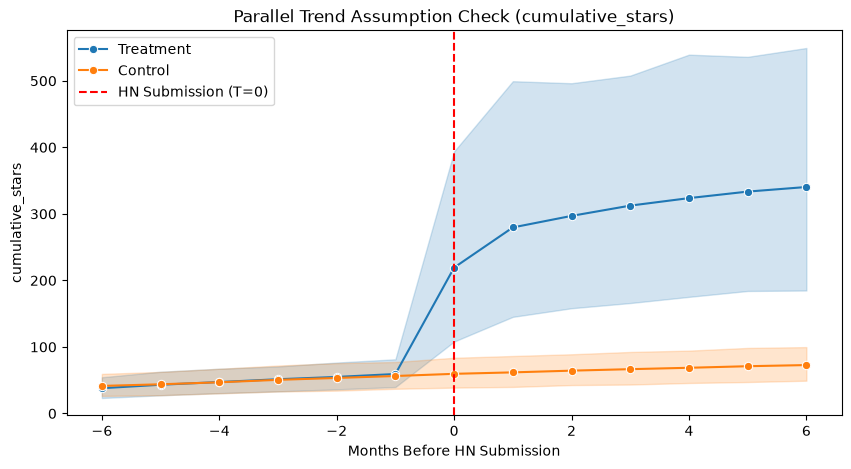

/tmp/ipykernel_30050/318001118.py:15: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


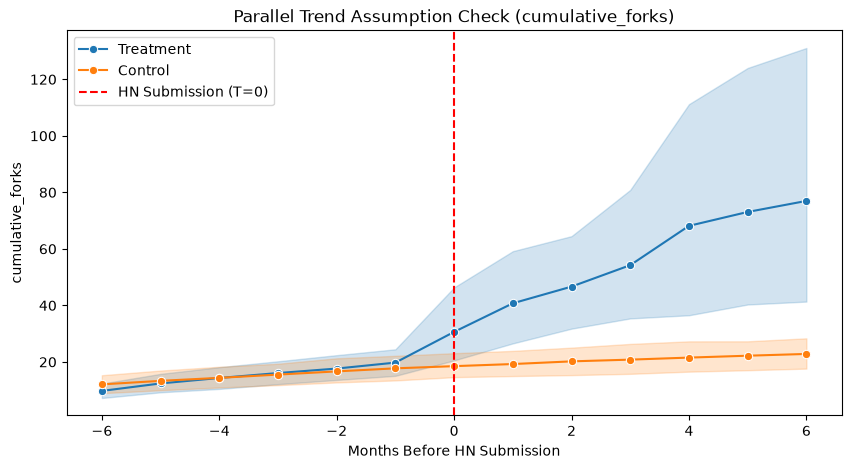

/tmp/ipykernel_30050/318001118.py:15: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


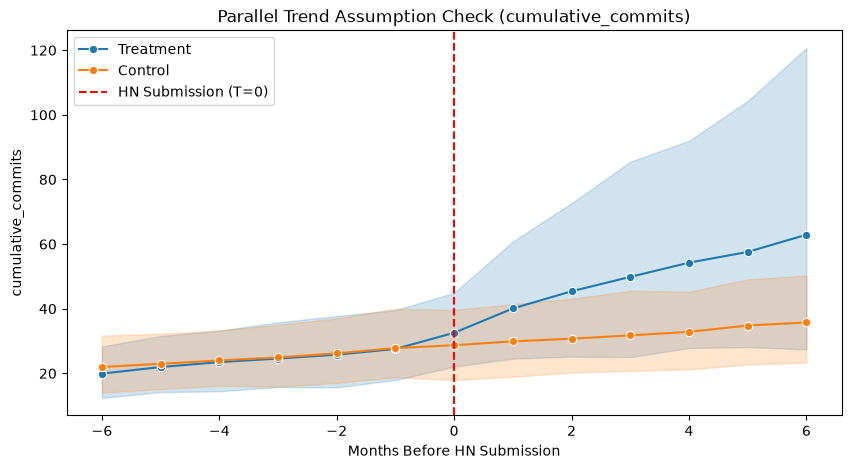

/tmp/ipykernel_30050/318001118.py:15: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


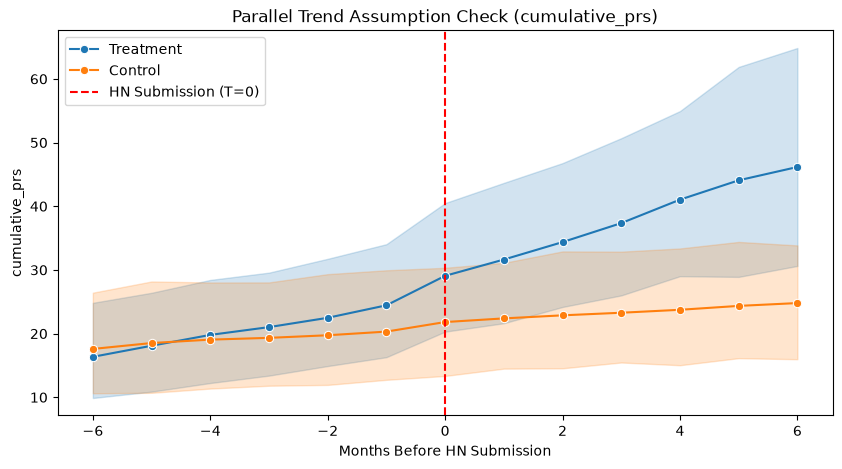

/tmp/ipykernel_30050/318001118.py:15: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


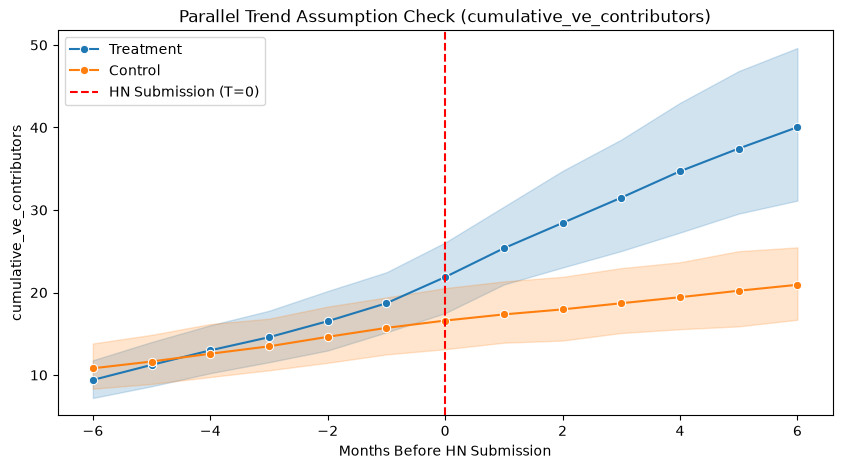

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Align time: Convert dates to relative months
def align_time(df, hn_date):
    hn_date = hn_date.tz_localize(None)  # Remove timezone
    df['relative_month'] = df['month'].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
    return df

# Aggregate trends: Average over all repos
def plot_aggregate_trend(metric):
    plt.figure(figsize=(10, 5))

    sns.lineplot(
        data=df_aligned,
        x="relative_month",
        y=metric,
        hue="repo_type",
        ci=95,  # Confidence interval
        marker="o"
    )
    # increase font size

    plt.axvline(x=0, color='red', linestyle='dashed', label="HN Submission (T=0)")
    plt.xlabel("Months Before HN Submission")
    plt.ylabel(metric)
    plt.title(f"Parallel Trend Assumption Check ({metric})")
    plt.legend()
    plt.show()

for metric in metrics:
    # Load matched treatment-control data
    df_matched = pd.read_csv(f"./matched_control_{metric}.csv")  # Adjust filename as needed

    # Convert date columns
    df_treatment['month'] = pd.to_datetime(df_treatment['month'])
    df_control['month'] = pd.to_datetime(df_control['month'])
    df_matched['hn_submission_date'] = pd.to_datetime(df_matched['hn_submission_date'])

    # Store aligned trends for aggregation
    aligned_treatment = []
    aligned_control = []

    # Iterate through matched pairs
    for _, row in df_matched.iterrows():
        treatment_repo = row['treatment_repo']
        control_repo = row['control_repo']
        hn_date = row['hn_submission_date']

        # Align treatment repo data
        treatment_data = df_treatment[df_treatment['repo_full_name'] == treatment_repo].copy()
        treatment_data = align_time(treatment_data, hn_date)
        treatment_data['repo_type'] = 'Treatment'
        aligned_treatment.append(treatment_data)

        # Align control repo data
        control_data = df_control[df_control['control_repo'] == control_repo].copy()
        control_data = align_time(control_data, hn_date)
        control_data['repo_type'] = 'Control'
        aligned_control.append(control_data)

    # Combine aligned data
    df_aligned = pd.concat(aligned_treatment + aligned_control, ignore_index=True)

    # Ensure relative_month is an integer for filtering
    df_aligned['relative_month'] = df_aligned['relative_month'].astype(int)

    # Filter for pre-submission period (T = -6 to -1)
    df_aligned = df_aligned[(df_aligned['relative_month'] >= -6) & (df_aligned['relative_month'] <= 6)]

    plot_aggregate_trend(metric)

## prepare dataset for -6 months and +6 months from HN submission date

In [19]:
import pandas as pd
from dateutil.relativedelta import relativedelta
import os

# Config
metrics = ['cumulative_stars', 'cumulative_forks', 'cumulative_commits', 'cumulative_prs', 'cumulative_ve_contributors']
output_dir = "aligned_did_outputs_v2_cumulative"
os.makedirs(output_dir, exist_ok=True)

# Load full cumulative metric files
df_treatment = pd.read_csv("../../dataset/hn-stories-gh-ai-metrics-[6months-before-after-hn]-cumulative-v2.csv", encoding="utf-7", parse_dates=["month", "hn_submission_date"])
df_control = pd.read_csv("../../dataset/nonhn-gh-ai-metrics-cumulative.csv", encoding="utf-7", parse_dates=["month"])

In [21]:
# Convert date columns
df_treatment['month'] = pd.to_datetime(df_treatment['month'])
df_control['month'] = pd.to_datetime(df_control['month'])

def align_time(df, hn_date):
    hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
    df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
    df["post_treatment"] = df["relative_month"].apply(lambda x: 1 if x >= 0 else 0)
    return df

for metric in metrics:
    df_matched = pd.read_csv(f"./matched_control_{metric}.csv", parse_dates=["hn_submission_date"])

    all_rows = []

    for _, row in df_matched.iterrows():
        treatment_repo = row['treatment_repo']
        control_repo = row['control_repo']
        hn_date = row['hn_submission_date']

        # Align treatment data
        treatment_data = df_treatment[df_treatment['repo_full_name'] == treatment_repo].copy()
        if treatment_data.empty:
            print(f"[Warning] No treatment data for: {treatment_repo}")
            continue

        treatment_data = align_time(treatment_data, hn_date)
        treatment_data["repo_type"] = "treatment"

        # Align control data
        control_data = df_control[df_control['control_repo'] == control_repo].copy()
        if control_data.empty:
            print(f"[Warning] No control data for: {control_repo}")
            continue

        control_data = align_time(control_data, hn_date)
        control_data["repo_type"] = "control"
        control_data = control_data.rename(columns={"control_repo": "repo_full_name"})

        # Combine
        combined = pd.concat([treatment_data, control_data], ignore_index=True)
        combined["pair_id"] = f"{treatment_repo}__vs__{control_repo}"
        all_rows.append(combined)

    if all_rows:
        df_final = pd.concat(all_rows, ignore_index=True)
        df_final = df_final[df_final['relative_month'].between(-6, 6)]
        df_final.to_csv(f"{output_dir}/aligned_did_{metric}.csv", index=False)
        print(f"[✓] Saved aligned_did_{metric}.csv")
    else:
        print(f"[x] No data found for {metric} — file skipped.")

/tmp/ipykernel_30050/3061114200.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/3061114200.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
/tmp/ipykernel_30050/3061114200.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/3061114200.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_peri

[✓] Saved aligned_did_cumulative_stars.csv


/tmp/ipykernel_30050/3061114200.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/3061114200.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
/tmp/ipykernel_30050/3061114200.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/3061114200.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_peri

[✓] Saved aligned_did_cumulative_forks.csv


/tmp/ipykernel_30050/3061114200.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/3061114200.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
/tmp/ipykernel_30050/3061114200.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/3061114200.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_peri

...

/tmp/ipykernel_30050/3061114200.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/3061114200.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
/tmp/ipykernel_30050/3061114200.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/3061114200.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_peri

[✓] Saved aligned_did_cumulative_prs.csv


/tmp/ipykernel_30050/3061114200.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/3061114200.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
/tmp/ipykernel_30050/3061114200.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/3061114200.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_peri

[✓] Saved aligned_did_cumulative_ve_contributors.csv


/tmp/ipykernel_30050/3061114200.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/3061114200.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_period("M")).n)
/tmp/ipykernel_30050/3061114200.py:6: Pandas4Warning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  hn_date = hn_date.tz_localize(None) if pd.api.types.is_datetime64tz_dtype(hn_date) else hn_date
/tmp/ipykernel_30050/3061114200.py:7: UserWarning: Converting to Period representation will drop timezone information.
  df["relative_month"] = df["month"].dt.to_period("M").apply(lambda x: (x - hn_date.to_peri

## export graphs
cross checking - generating PTA graph using the new relative-months file

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set up
aligned_dir = "aligned_did_outputs_v2_cumulative"
metrics = ['cumulative_stars', 'cumulative_forks', 'cumulative_commits', 'cumulative_prs', 'cumulative_ve_contributors']
metric_column_map = {
    "cumulative_stars": "cumulative_stars",
    "cumulative_forks": "cumulative_forks",
    "cumulative_commits": "cumulative_commits",
    "cumulative_prs": "cumulative_prs",
    "cumulative_ve_contributors": "cumulative_ve_contributors"
}


/tmp/ipykernel_30050/3574555197.py:17: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


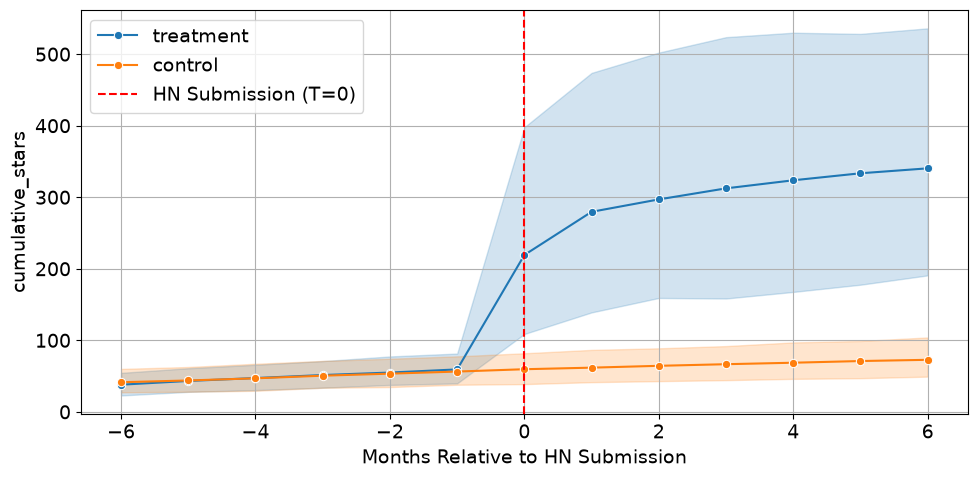

/tmp/ipykernel_30050/3574555197.py:17: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


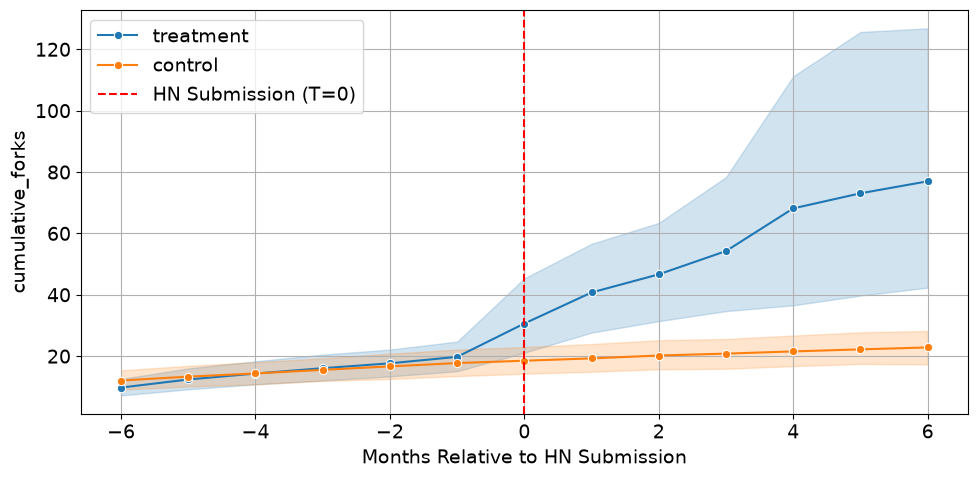

/tmp/ipykernel_30050/3574555197.py:17: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


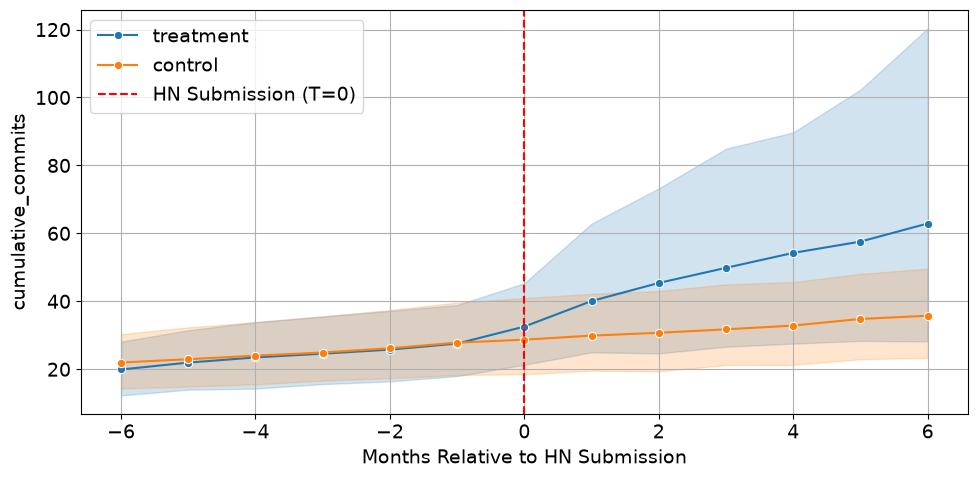

/tmp/ipykernel_30050/3574555197.py:17: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


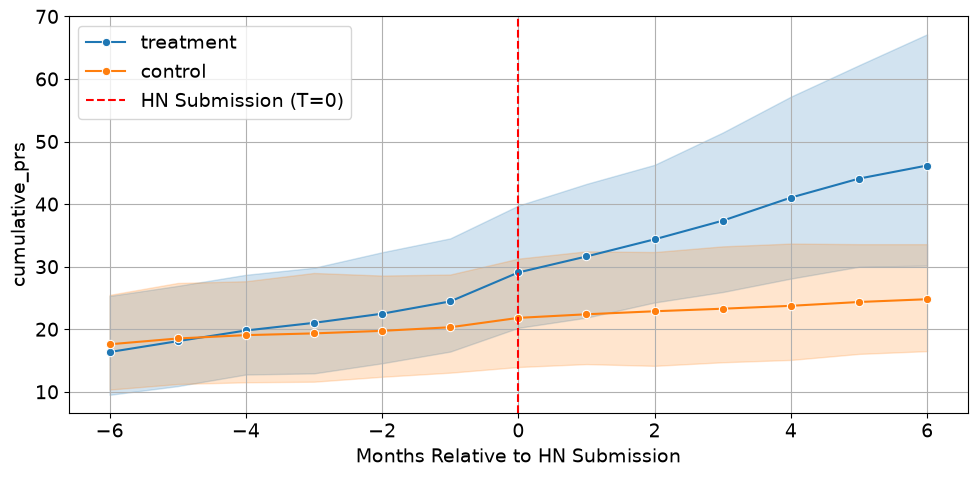

/tmp/ipykernel_30050/3574555197.py:17: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


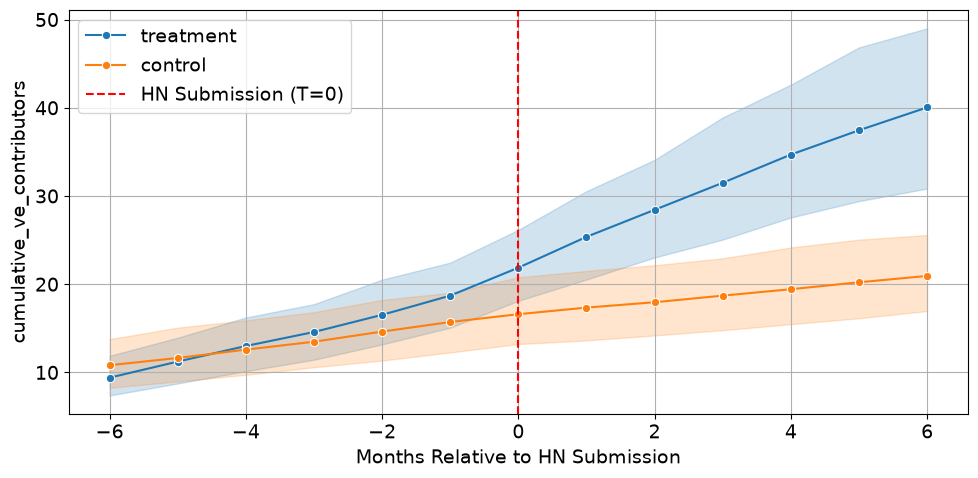

In [42]:
# Plot function
def plot_aggregate_trend(metric_key):
    file_path = os.path.join(aligned_dir, f"aligned_did_{metric_key}.csv")
    if not os.path.exists(file_path):
        print(f"[!] File not found: {file_path}")
        return

    df = pd.read_csv(file_path)
    if df.empty:
        print(f"[!] Empty data in {file_path}")
        return

    df["relative_month"] = df["relative_month"].astype(int)
    metric_col = metric_column_map[metric_key]

    plt.figure(figsize=(10, 5))
    sns.lineplot(
        data=df,
        x="relative_month",
        y=metric_col,
        hue="repo_type",
        ci=95,
        marker="o"
    )
    # increase font size
    plt.rcParams.update({'font.size': 14})

    plt.axvline(x=0, color='red', linestyle='dashed', label="HN Submission (T=0)")
    plt.xlabel("Months Relative to HN Submission")
    plt.ylabel(metric_col)
    # plt.title(f"Parallel Trend Check (Cumulative {metric_key.title()})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"plots/parallel_trend_check_{metric_key}.pdf")
    plt.show()

# Run for each metric
for metric in metrics:
    plot_aggregate_trend(metric)

## export graphs -show outliers

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set up
aligned_dir = "aligned_did_outputs_v2_cumulative"
metrics = ['cumulative_stars', 'cumulative_forks', 'cumulative_commits', 'cumulative_prs', 'cumulative_ve_contributors']
metric_column_map = {
    "cumulative_stars": "cumulative_stars",
    "cumulative_forks": "cumulative_forks",
    "cumulative_commits": "cumulative_commits",
    "cumulative_prs": "cumulative_prs",
    "cumulative_ve_contributors": "cumulative_ve_contributors"
}


# Set up
# aligned_dir = "aligned_did_outputs"
# metrics = ['stars', 'forks', 'commits', 'prs', 've_contributors']
# metric_column_map = {
#     "stars": "cumulative_stars",
#     "forks": "cumulative_forks",
#     "commits": "cumulative_commits",
#     "prs": "cumulative_prs",
#     "ve_contributors": "cumulative_ve_contributors"
# }

/tmp/ipykernel_30050/803048017.py:33: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


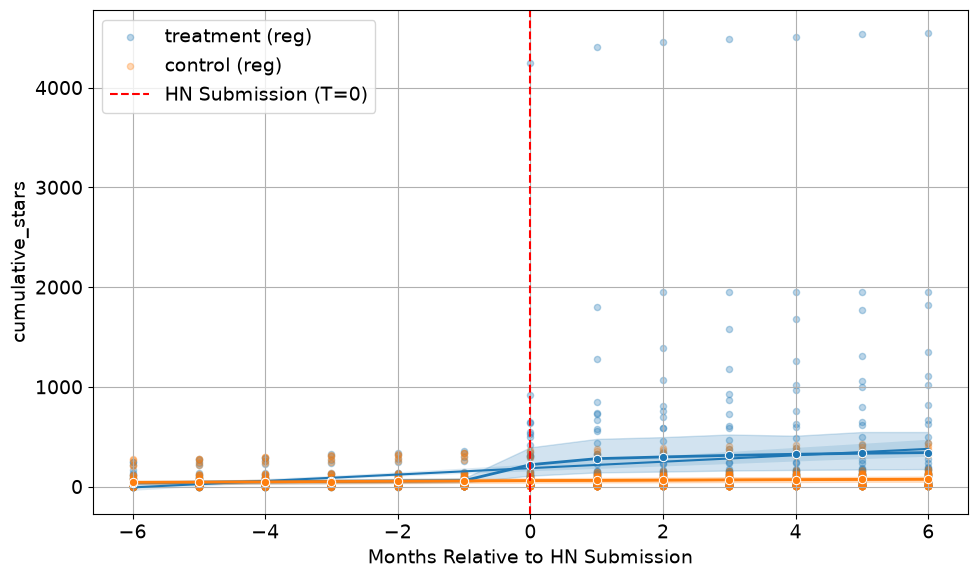

/tmp/ipykernel_30050/803048017.py:33: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


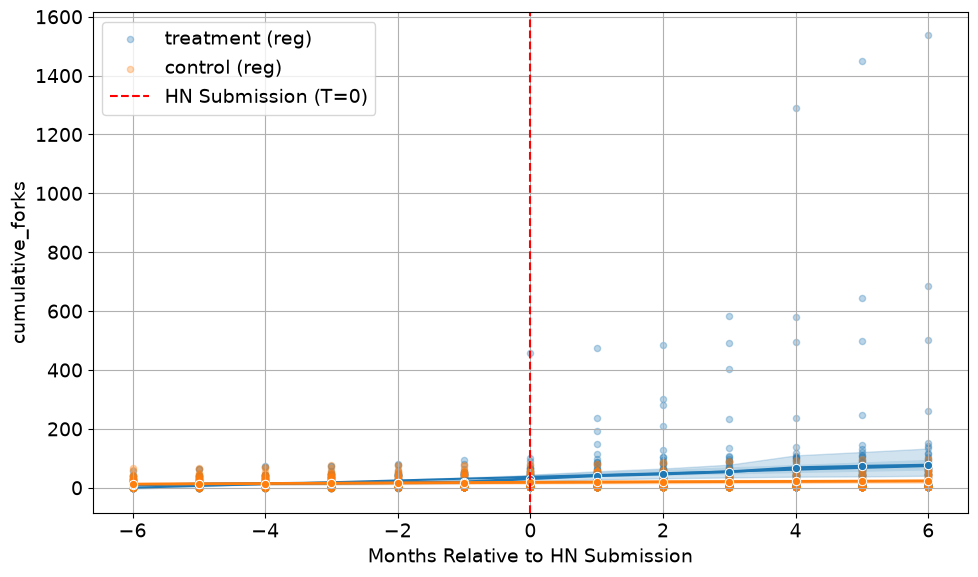

/tmp/ipykernel_30050/803048017.py:33: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


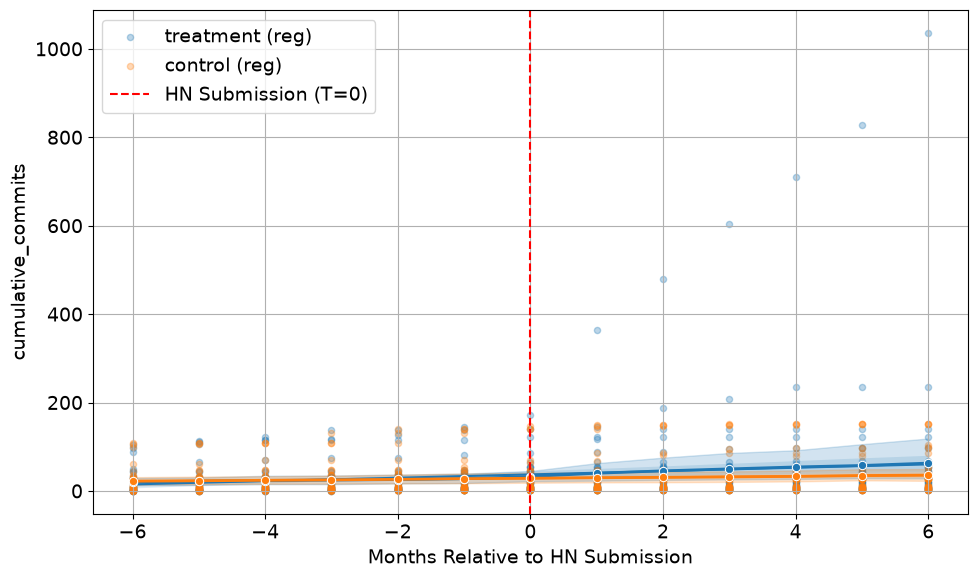

/tmp/ipykernel_30050/803048017.py:33: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


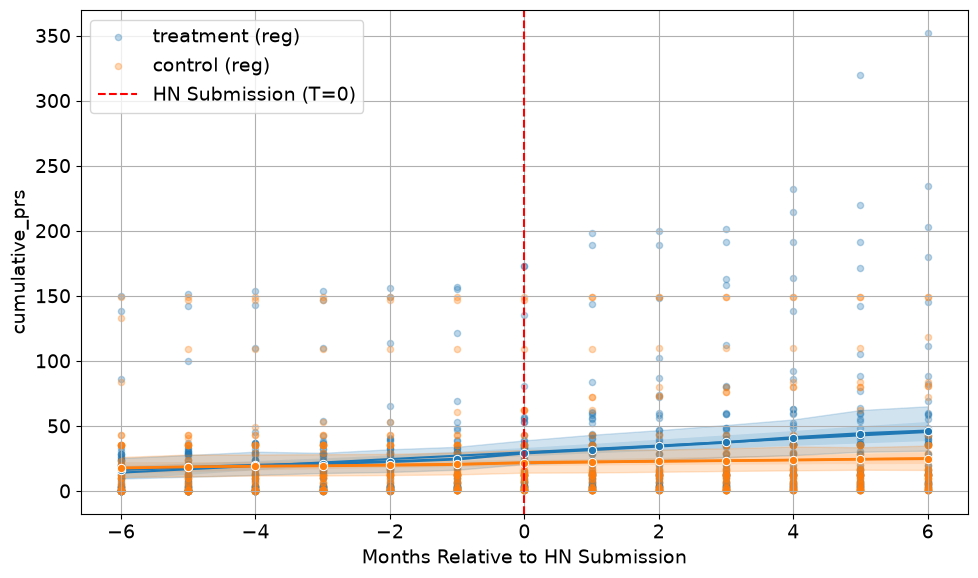

/tmp/ipykernel_30050/803048017.py:33: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


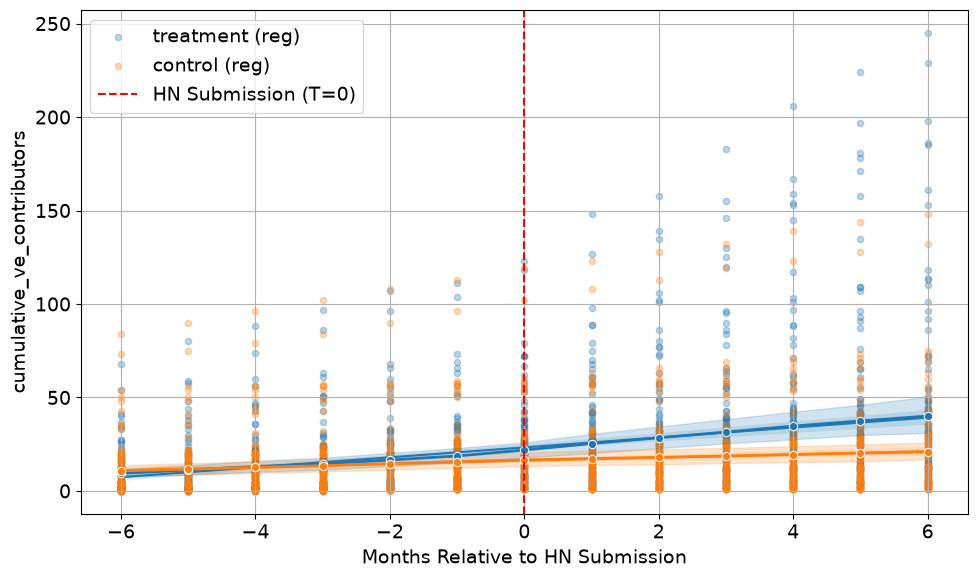

In [40]:
# Plot function
def plot_aggregate_trend(metric_key):
    file_path = os.path.join(aligned_dir, f"aligned_did_{metric_key}.csv")
    if not os.path.exists(file_path):
        print(f"[!] File not found: {file_path}")
        return

    df = pd.read_csv(file_path)
    if df.empty:
        print(f"[!] Empty data in {file_path}")
        return

    df["relative_month"] = df["relative_month"].astype(int)
    metric_col = metric_column_map[metric_key]

    plt.figure(figsize=(10, 6))

    # Scatterplot with regression line, split by group
    for repo_type in df["repo_type"].unique():
        subset = df[df["repo_type"] == repo_type]
        sns.regplot(
            data=subset,
            x="relative_month",
            y=metric_col,
            scatter=True,
            lowess=False,
            label=f"{repo_type} (reg)",
            scatter_kws={'alpha':0.3, 's':20},
            line_kws={'linewidth':1.5}
        )

    # Original lineplot for smoothed group means
    sns.lineplot(
        data=df,
        x="relative_month",
        y=metric_col,
        hue="repo_type",
        ci=95,
        marker="o",
        linewidth=2,
        legend=False  # Already have labels from regplot
    )
    # increase font size
    plt.rcParams.update({'font.size': 14})

    plt.axvline(x=0, color='red', linestyle='dashed', label="HN Submission (T=0)")
    plt.xlabel("Months Relative to HN Submission")
    plt.ylabel(metric_col)
    # plt.title(f"Parallel Trend Check with Scatter & Regression\n(Cumulative {metric_key.title()})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"plots/parallel_trend_check_with_scatter_{metric_key}.pdf")
    plt.show()

# Run for each metric
for metric in metrics:
    plot_aggregate_trend(metric)